In [1]:
import torch
import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor

In [2]:
train_data = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)

test_data = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor()
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 493kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.55MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.60MB/s]


In [3]:
print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

Training samples: 60000
Testing samples: 10000


In [4]:
image, label = train_data[0]

print("Image shape:", image.shape)
print("Label:", label)

Image shape: torch.Size([1, 28, 28])
Label: 5


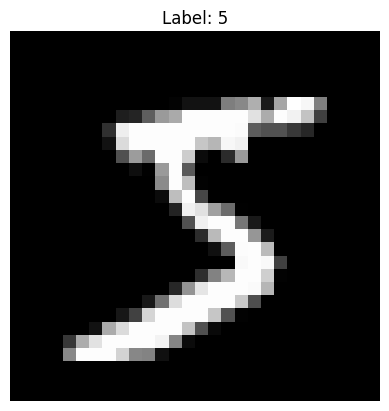

In [5]:
import matplotlib.pyplot as plt
image, label = train_data[0]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

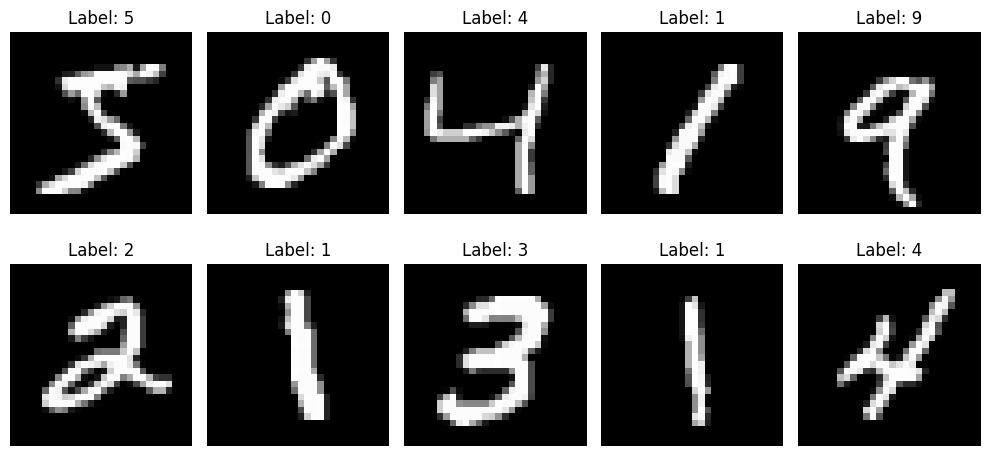

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=32,
    shuffle=False
)

In [9]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([32, 1, 28, 28])
Labels shape: torch.Size([32])


In [10]:
import torch.nn as nn

class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.network = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.network(x)


model = DigitClassifier()

print(model)

DigitClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [11]:
images, labels = next(iter(train_loader))

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 1, 28, 28])
Output shape: torch.Size([32, 10])


In [12]:
print(outputs[0])
print("Actual label:", labels[0])

tensor([ 0.1199,  0.0462,  0.0893, -0.0006,  0.0031,  0.0132,  0.1731,  0.0652,
        -0.0167,  0.0482], grad_fn=<SelectBackward0>)
Actual label: tensor(0)


In [13]:
prediction = torch.argmax(outputs[0])

print("Predicted digit:", prediction.item())
print("Actual digit:", labels[0].item())

Predicted digit: 6
Actual digit: 0


In [14]:
import torch.nn as nn

loss_fn = nn.CrossEntropyLoss()

print(loss_fn)

CrossEntropyLoss()


In [15]:
loss = loss_fn(outputs, labels)

print("Loss:", loss.item())

Loss: 2.2889976501464844


In [16]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [17]:
epochs = 5

for epoch in range(epochs):
    model.train()

    total_loss = 0

    for images, labels in train_loader:
        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = loss_fn(outputs, labels)

        # Clear old gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(f"Epoch {epoch + 1}/{epochs}, Loss: {average_loss:.4f}")

Epoch 1/5, Loss: 0.2989
Epoch 2/5, Loss: 0.1298
Epoch 3/5, Loss: 0.0886
Epoch 4/5, Loss: 0.0670
Epoch 5/5, Loss: 0.0519


In [18]:
correct = 0
total = 0

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 97.64%


In [19]:
torch.save(model.state_dict(), "mnist_digit_classifier.pth")

In [20]:
import os

print(os.path.getsize("mnist_digit_classifier.pth") / 1024, "KB")

400.2373046875 KB


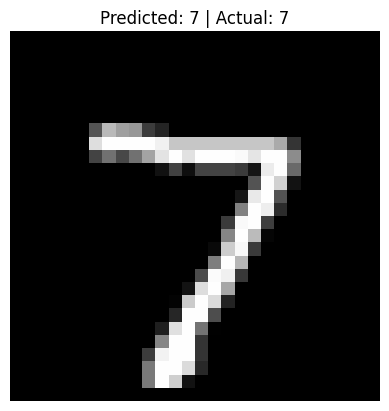

In [21]:
import matplotlib.pyplot as plt

model.eval()

image, label = test_data[0]

with torch.no_grad():
    output = model(image.unsqueeze(0))
    prediction = torch.argmax(output, dim=1).item()

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Predicted: {prediction} | Actual: {label}")
plt.axis("off")
plt.show()